Observed Weather Distribution:
Sunny: 0.5
Cloudy: 0.3
Rainy: 0.2

Entropy of Observed Distribution:
H(P) = 1.4855 bits

Model 1 Results:
Cross Entropy = 1.4855 bits
KL Divergence = 0.0 bits

Model 2 Results:
Cross Entropy = 1.6183 bits
KL Divergence = 0.1328 bits

Verification for Model 1:
Cross Entropy = 1.4854752972273344
Entropy + KL = 1.4854752972273346

Verification for Model 2:
Cross Entropy = 1.6182506338585605
Entropy + KL = 1.6182506338585605

Model 1 Verification: True
Model 2 Verification: True

KL Divergence Asymmetry:
KL(P || Q1) = 0.0
KL(Q1 || P) = 0.0


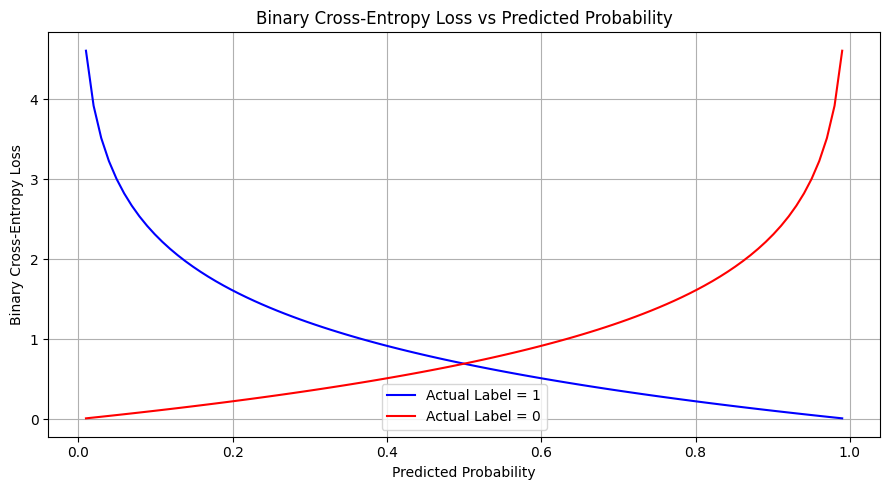

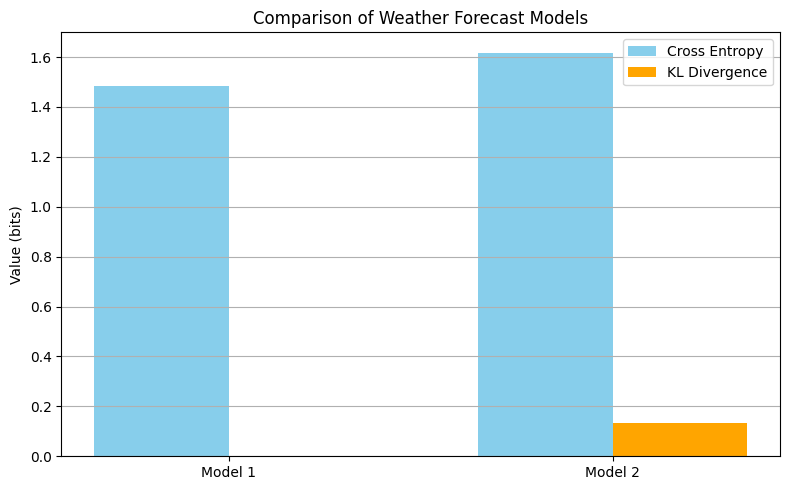

In [5]:

# Experiment 4: Entropy, Cross-Entropy and KL Divergence

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# ------------------------------------------------
# TASK 1: Entropy of Observed Weather Distribution
# ------------------------------------------------

# Observed weather data for 30 days
# Sunny = 15 days, Cloudy = 9 days, Rainy = 6 days

true_counts = np.array([15, 9, 6])

# Convert counts into probabilities
P = true_counts / np.sum(true_counts)

print("Observed Weather Distribution:")
print("Sunny:", P[0])
print("Cloudy:", P[1])
print("Rainy:", P[2])

# Calculate entropy
H_P = entropy(P, base=2)

print("\nEntropy of Observed Distribution:")
print("H(P) =", round(H_P, 4), "bits")


# ------------------------------------------------
# TASK 2: Cross-Entropy and KL Divergence
# ------------------------------------------------

# Model 1 predictions
Q1 = np.array([0.50, 0.30, 0.20])

# Model 2 predictions
Q2 = np.array([0.70, 0.20, 0.10])

# Calculate cross-entropy
def cross_entropy(P, Q):
    return -np.sum(P * np.log2(Q))

# Calculate KL divergence
def kl_divergence(P, Q):
    return np.sum(P * np.log2(P / Q))

# Model 1 calculations
CE1 = cross_entropy(P, Q1)
KL1 = kl_divergence(P, Q1)

# Model 2 calculations
CE2 = cross_entropy(P, Q2)
KL2 = kl_divergence(P, Q2)

print("\nModel 1 Results:")
print("Cross Entropy =", round(CE1, 4), "bits")
print("KL Divergence =", round(KL1, 4), "bits")

print("\nModel 2 Results:")
print("Cross Entropy =", round(CE2, 4), "bits")
print("KL Divergence =", round(KL2, 4), "bits")


# ------------------------------------------------
# TASK 3: Verify Cross Entropy = Entropy + KL
# ------------------------------------------------

print("\nVerification for Model 1:")

print("Cross Entropy =", CE1)
print("Entropy + KL =", H_P + KL1)

print("\nVerification for Model 2:")

print("Cross Entropy =", CE2)
print("Entropy + KL =", H_P + KL2)

# Check equality
print("\nModel 1 Verification:",
      np.isclose(CE1, H_P + KL1))

print("Model 2 Verification:",
      np.isclose(CE2, H_P + KL2))


# ------------------------------------------------
# TASK 4: KL Divergence is Asymmetric
# ------------------------------------------------

# KL(P || Q1)
KL_PQ = kl_divergence(P, Q1)

# KL(Q1 || P)
KL_QP = kl_divergence(Q1, P)

print("\nKL Divergence Asymmetry:")

print("KL(P || Q1) =", round(KL_PQ, 4))
print("KL(Q1 || P) =", round(KL_QP, 4))

if not np.isclose(KL_PQ, KL_QP):
    print("KL Divergence is Asymmetric")


# ------------------------------------------------
# TASK 5: Binary Cross-Entropy Loss
# ------------------------------------------------

# Actual binary label
y_true = 1

# Predicted probabilities
predicted_probabilities = np.linspace(0.01, 0.99, 100)

# Binary Cross-Entropy Formula
def binary_cross_entropy(y, p):
    return -(y * np.log(p) +
             (1 - y) * np.log(1 - p))

# Calculate loss for actual label 1
loss_positive = binary_cross_entropy(
    y_true, predicted_probabilities
)

# Calculate loss for actual label 0
loss_negative = binary_cross_entropy(
    0, predicted_probabilities
)

# Plot binary cross-entropy
plt.figure(figsize=(9, 5))

plt.plot(
    predicted_probabilities,
    loss_positive,
    color='blue',
    label='Actual Label = 1'
)

plt.plot(
    predicted_probabilities,
    loss_negative,
    color='red',
    label='Actual Label = 0'
)

plt.xlabel("Predicted Probability")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title("Binary Cross-Entropy Loss vs Predicted Probability")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------
# Compare Both Weather Models
# ------------------------------------------------

models = ['Model 1', 'Model 2']

cross_entropy_values = [CE1, CE2]
kl_values = [KL1, KL2]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    cross_entropy_values,
    width,
    label='Cross Entropy',
    color='skyblue'
)

plt.bar(
    x + width/2,
    kl_values,
    width,
    label='KL Divergence',
    color='orange'
)

plt.xticks(x, models)
plt.ylabel("Value (bits)")
plt.title("Comparison of Weather Forecast Models")

plt.legend()
plt.grid(axis='y')

plt.tight_layout()
plt.show()
